# Compare Earth embeddings with one API

Choose a model with `get_embedding(model, spatial=..., temporal=..., output=...)`; compare a list with `compare_embeddings` and one plotting call. This notebook first displays the published real 22-model gallery, then executes three lightweight location encoders on one regional query grid. The full 22-model extraction is an explicit optional step.

Install from the repository with `python -m pip install -e ".[demo,location]"`. Image/product extraction also needs model runtimes, weights and provider access. The displayed Wuhan gallery reuses historical cache outputs; it is not regenerated by the location example or a performance ranking.

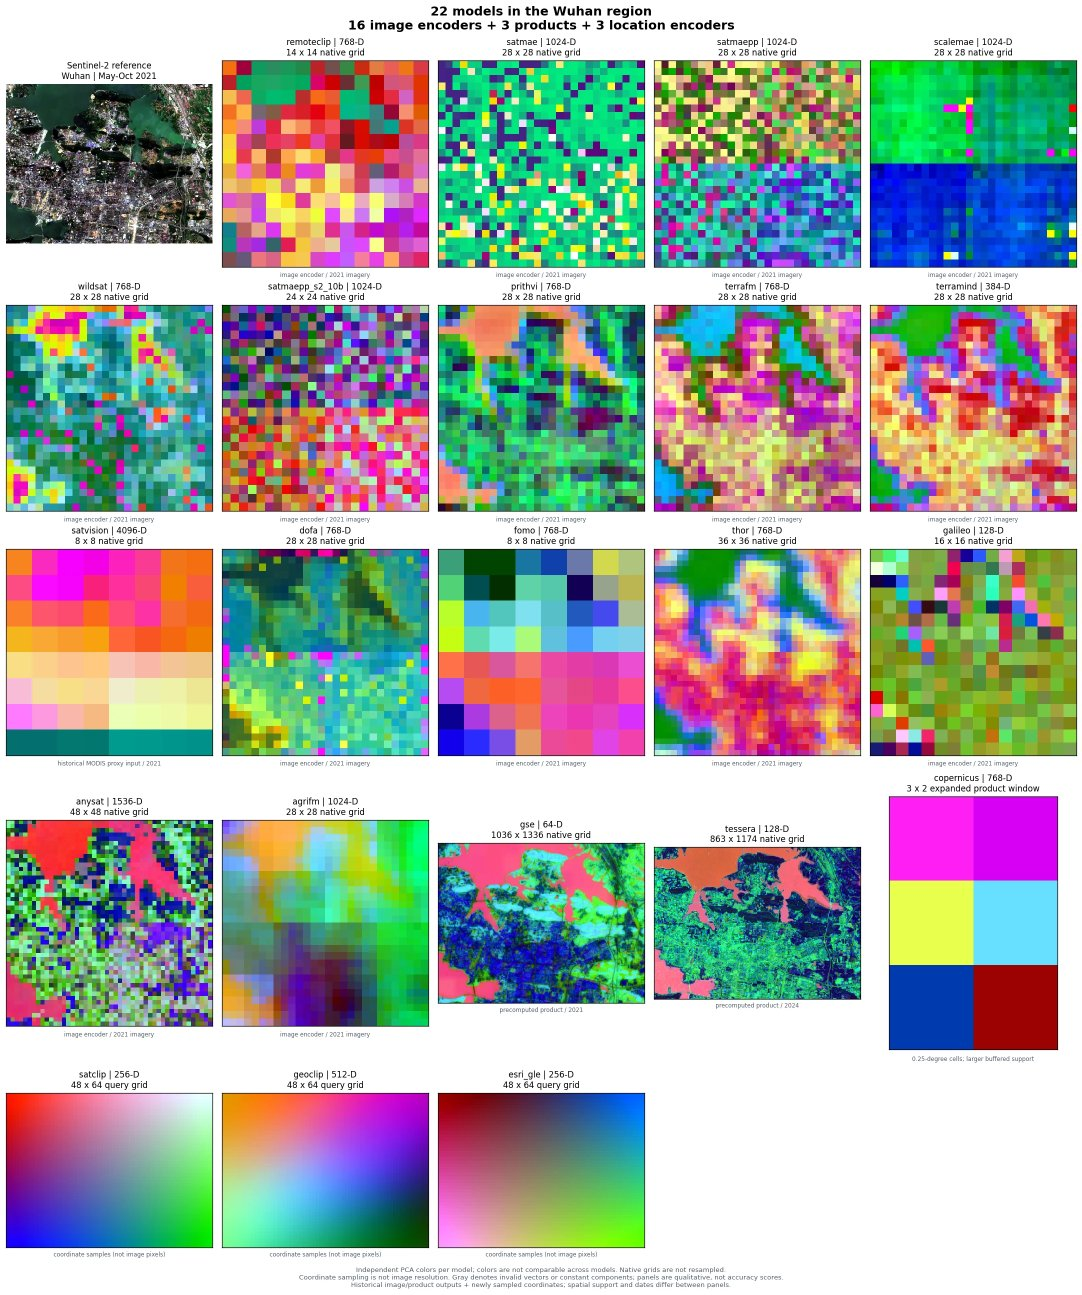

In [1]:
import io
from pathlib import Path
from IPython.display import Image, display
from PIL import Image as PILImage

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
# Half-resolution preview; the full figure is docs/assets/comparison/all-models.webp.
gallery = PILImage.open(root / "docs/assets/comparison/all-models.webp").convert("RGB").reduce(2)
buffer = io.BytesIO()
gallery.save(buffer, format="JPEG", quality=85)
display(Image(data=buffer.getvalue(), format="jpeg", width=1000))

## Discover models and their weights

Resource discovery is offline and does not load a model. Hugging Face checkpoint links, existing embedding datasets, and author-hosted releases are distinguished.

In [2]:
import pandas as pd
from earth_embedding import list_model_resources

resources = pd.DataFrame(list_model_resources())
resources[['model_id', 'category', 'input', 'weights_kind', 'weights_url']]

,model_id,category,input,weights_kind,weights_url
0,remoteclip,image,Sentinel-2 RGB,Hugging Face model,https://huggingface.co/MVRL/remote-clip-vit-ba...
1,satmae,image,Sentinel-2 RGB,Hugging Face model,https://huggingface.co/MVRL/satmae-vitlarge-fm...
2,satmaepp,image,Sentinel-2 RGB,Hugging Face model,https://huggingface.co/MVRL/satmaepp_ViT-L_pre...
3,satmaepp_s2_10b,image,Sentinel-2 10 bands,Hugging Face model,https://huggingface.co/mubashir04/checkpoint_V...
4,scalemae,image,Sentinel-2 RGB + ground resolution,Hugging Face model,https://huggingface.co/MVRL/scalemae-vitlarge-800
5,wildsat,image,Sentinel-2 RGB,official download,https://github.com/cvl-umass/wildsat#quickstart
6,prithvi,image,Sentinel-2 6 bands + time/location,Hugging Face model,https://huggingface.co/ibm-nasa-geospatial/Pri...
7,terrafm,image,Sentinel-2 12 bands or Sentinel-1 VV/VH,Hugging Face model,https://huggingface.co/MBZUAI/TerraFM
8,terramind,image,Sentinel-2 12 bands,Hugging Face model,https://huggingface.co/ibm-esa-geospatial/Terr...
9,dofa,image,Multispectral imagery + wavelengths,Hugging Face model,https://huggingface.co/earthflow/DOFA


## Three location encoders, one figure

The same `BBox` and 5 km query spacing are sent to SatCLIP, GeoCLIP and Esri GLE. The result describes coordinate priors; it has no observation year. CPU inference uses official pretrained weights and may download them on first use.

In [3]:
from earth_embedding import (
    BBox, OutputSpec, TemporalSpec, get_embedding,
    compare_embeddings, plot_embedding_comparison,
)

models = ['satclip', 'geoclip', 'esri_gle']
spatial = BBox(113.9, 30.2, 114.7, 30.9)
output = OutputSpec.grid()

comparison = compare_embeddings(
    models, spatial=spatial, output=output, device='cpu',
    model_options={model: {'grid_step_m': 5000, 'batch_size': 128} for model in models},
)
comparison.summary()

{'satclip': {'status': 'ok', 'shape': [256, 16, 16]},
 'geoclip': {'status': 'ok', 'shape': [512, 16, 16]},
 'esri_gle': {'status': 'ok', 'shape': [256, 16, 16]}}

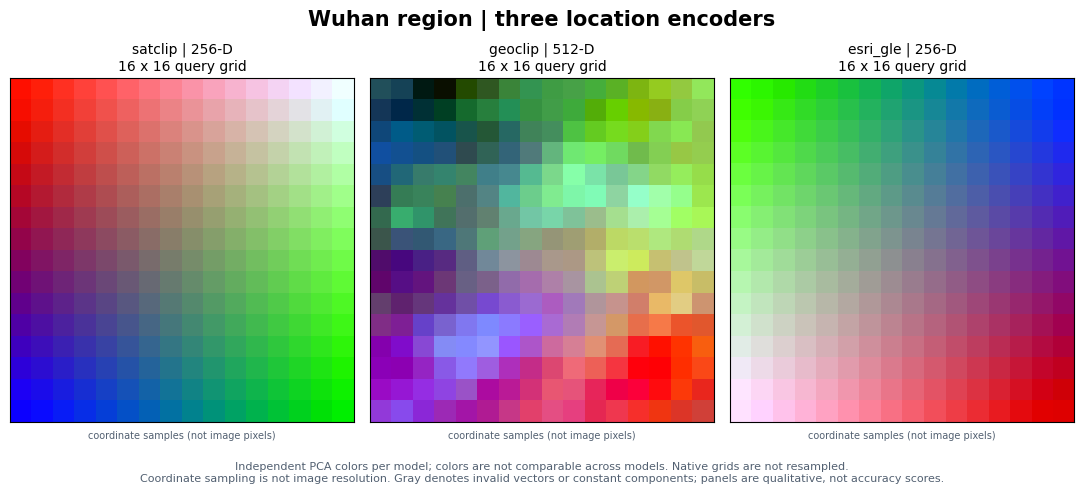

In [4]:
import matplotlib.pyplot as plt
fig = plot_embedding_comparison(comparison, columns=3, title='Wuhan region | three location encoders')
display(fig)
plt.close(fig)

## One model, or all 22

A single image model uses the same entry point:

```python
temporal = TemporalSpec.range('2021-05-01', '2021-10-31')
emb = get_embedding('prithvi', spatial=spatial, temporal=temporal, output=output)
```

The next cell is disabled by default: the full catalog downloads large weights and requests imagery/products. Use a modest image ROI, and set annual dates separately from the image window. Setting `RUN_ALL_MODELS=True` runs genuine extraction, saving successes and reporting failures.

In [5]:
RUN_ALL_MODELS = False

if RUN_ALL_MODELS:
    from earth_embedding import PointBuffer
    options = {model: {'temporal': TemporalSpec.year(2021)}
               for model in ('gse', 'tessera', 'copernicus')}
    options.update({model: {'temporal': None, 'grid_step_m': 80}
                    for model in ('satclip', 'geoclip', 'esri_gle')})
    all_models = compare_embeddings(
        spatial=PointBuffer(lon=114.41, lat=30.52, buffer_m=640),
        temporal=TemporalSpec.range('2021-05-01', '2021-10-31'),
        output=OutputSpec.grid(), model_options=options, on_error='record',
    )
    display(all_models.summary())
    fig = plot_embedding_comparison(all_models, columns=5)
    display(fig)
    plt.close(fig)
else:
    print('Full model extraction is optional. Set RUN_ALL_MODELS=True after configuring data access.')

Full model extraction is optional. Set RUN_ALL_MODELS=True after configuring data access.


## Save and interpret

Use `python examples/compare_models.py --models all --out outputs/comparison` for a PNG, per-model NPZ features, and a JSON report. Each panel uses independent PCA colors; feature axes, output resolutions, and time semantics differ across models. Constant components and invalid vectors appear gray. A missing model is recorded explicitly, never replaced with generated data.

[Full tutorial](../../docs/tutorials/model-comparison.md) · [Resources](../../docs/model-resources.md) · [Gallery provenance](../../docs/assets/comparison/provenance.json)